# Notebook 04 — Exploratory Data Analysis

Detailed EDA is performed using the training split only to understand data quality, distributions, relationships, temporal patterns, and geography before feature engineering.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent

TRAIN_PATH = PROJECT_ROOT / "artifacts" / "03_splits" / "train.parquet"

CHARTS_DIR = PROJECT_ROOT / "artifacts" / "04_eda" / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_parquet(TRAIN_PATH)

print("Shape:", train_df.shape)
display(train_df.head())

Shape: (67529, 39)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,unique_seller_state_count,mean_product_weight_g,max_product_weight_g,mean_product_length_cm,mean_product_height_cm,mean_product_width_cm,mean_seller_latitude,mean_seller_longitude,is_late,delivery_label
0,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04,830d5b7aaa3b6f1e9ad63703bec97d23,14600,...,1.0,1000.0,1000.0,16.0,16.0,16.0,-25.507014,-49.275963,1,Late
1,3b697a20d9e427646d92567910af6d57,355077684019f7f60a031656bd7262b8,delivered,2016-10-03 09:44:50,2016-10-06 15:50:54,2016-10-23 14:02:13,2016-10-26 14:02:13,2016-10-27,32ea3bdedab835c3aa6cb68ce66565ef,4106,...,1.0,300.0,300.0,16.0,16.0,16.0,-24.959184,-53.462644,0,On Time
2,be5bc2f0da14d8071e2d45451ad119d9,7ec40b22510fdbea1b08921dd39e63d8,delivered,2016-10-03 16:56:50,2016-10-06 16:03:44,2016-10-21 16:33:46,2016-10-27 18:19:38,2016-11-07,2f64e403852e6893ae37485d5fcacdaf,98280,...,1.0,400.0,400.0,16.0,16.0,16.0,-21.143389,-48.995314,0,On Time
3,a41c8759fbe7aab36ea07e038b2d4465,6f989332712d3222b6571b1cf5b835ce,delivered,2016-10-03 21:13:36,2016-10-05 03:11:49,2016-10-25 11:57:59,2016-11-03 10:58:07,2016-11-29,61db744d2f835035a5625b59350c6b63,90040,...,1.0,767.0,767.0,26.0,8.0,20.0,-23.502755,-47.430451,0,On Time
4,d207cc272675637bfed0062edffd0818,b8cf418e97ae795672d326288dfab7a7,delivered,2016-10-03 22:06:03,2016-10-04 10:28:07,2016-10-21 14:23:37,2016-10-31 11:07:42,2016-11-23,8d3a54507421dbd2ce0a1d58046826e0,13185,...,1.0,2050.0,2050.0,40.0,11.0,34.0,-21.757321,-48.829744,0,On Time


In [3]:
print("Shape:", train_df.shape)

print("\nData types:")
display(train_df.dtypes.to_frame("dtype"))

memory_mb = train_df.memory_usage(deep=True).sum() / 1024**2
print(f"\nMemory usage: {memory_mb:.2f} MB")

Shape: (67529, 39)

Data types:


,dtype
order_id,str
customer_id,str
order_status,str
order_purchase_timestamp,datetime64[us]
order_approved_at,datetime64[us]
order_delivered_carrier_date,datetime64[us]
order_delivered_customer_date,datetime64[us]
order_estimated_delivery_date,datetime64[us]
customer_unique_id,str
customer_zip_code_prefix,int64



Memory usage: 27.63 MB


In [4]:
numerical_cols = train_df.select_dtypes(include="number").columns.tolist()
categorical_cols = train_df.select_dtypes(include=["object", "category"]).columns.tolist()
date_cols = train_df.select_dtypes(include=["datetime", "datetimetz"]).columns.tolist()

print("Numerical:", numerical_cols)
print("\nCategorical:", categorical_cols)
print("\nDates:", date_cols)

Numerical: ['customer_zip_code_prefix', 'item_count', 'unique_product_count', 'unique_seller_count_x', 'total_item_price', 'mean_item_price', 'max_item_price', 'total_freight_value', 'payment_count', 'payment_type_count', 'max_payment_installments', 'total_payment_value', 'review_count', 'mean_review_score', 'min_review_score', 'max_review_score', 'unique_category_count', 'unique_seller_count_y', 'unique_seller_state_count', 'mean_product_weight_g', 'max_product_weight_g', 'mean_product_length_cm', 'mean_product_height_cm', 'mean_product_width_cm', 'mean_seller_latitude', 'mean_seller_longitude', 'is_late']

Categorical: ['order_id', 'customer_id', 'order_status', 'customer_unique_id', 'customer_city', 'customer_state', 'delivery_label']

Dates: ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


C:\Users\CW\AppData\Local\Temp\ipykernel_19732\3483679827.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_df.select_dtypes(include=["object", "category"]).columns.tolist()


In [5]:
id_cols = [
    "order_id",
    "customer_id",
    "customer_unique_id"
]

print("ID columns:", id_cols)

ID columns: ['order_id', 'customer_id', 'customer_unique_id']


## Missing Values

In [7]:
missing = pd.DataFrame({
    "missing_count": train_df.isna().sum(),
    "missing_%": train_df.isna().mean().mul(100).round(2)
})

missing = missing[missing["missing_count"] > 0]
missing = missing.sort_values("missing_%", ascending=False)

display(missing)

,missing_count,missing_%
mean_review_score,515,0.76
review_count,515,0.76
min_review_score,515,0.76
max_review_score,515,0.76
mean_seller_longitude,164,0.24
mean_seller_latitude,164,0.24
order_approved_at,14,0.02
mean_product_weight_g,16,0.02
mean_product_length_cm,16,0.02
mean_product_width_cm,16,0.02


In [8]:
display(train_df[numerical_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
customer_zip_code_prefix,67529.0,36010.051889,29908.242352,1004.000000,12061.000000,25959.000000,60360.000000,99980.000000
item_count,67529.0,1.142072,0.541640,1.000000,1.000000,1.000000,1.000000,21.000000
unique_product_count,67529.0,1.037702,0.222199,1.000000,1.000000,1.000000,1.000000,7.000000
unique_seller_count_x,67529.0,1.012054,0.114815,1.000000,1.000000,1.000000,1.000000,5.000000
total_item_price,67529.0,135.888797,205.194019,2.290000,45.900000,85.000000,149.900000,13440.000000
mean_item_price,67529.0,124.239070,185.659661,1.514286,41.000000,78.970000,139.900000,6735.000000
max_item_price,67529.0,124.847354,186.037538,2.290000,41.900000,79.000000,139.900000,6735.000000
total_freight_value,67529.0,22.245936,20.002594,0.000000,14.100000,16.790000,23.700000,1002.290000
payment_count,67528.0,1.047625,0.397223,1.000000,1.000000,1.000000,1.000000,26.000000
payment_type_count,67528.0,1.024020,0.153111,1.000000,1.000000,1.000000,1.000000,2.000000


In [9]:
skewness = (
    train_df[numerical_cols]
    .skew()
    .sort_values(ascending=False)
    .to_frame("skewness")
)

display(skewness)

,skewness
payment_count,22.419509
unique_seller_state_count,15.177527
review_count,11.886516
total_item_price,10.718895
unique_seller_count_y,10.524938
unique_seller_count_x,10.524938
total_payment_value,10.149318
total_freight_value,8.581743
item_count,8.107162
mean_item_price,7.802465


In [10]:
outlier_summary = []

for col in numerical_cols:
    if col == "is_late":
        continue

    series = train_df[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = ((series < lower) | (series > upper)).sum()

    outlier_summary.append({
        "column": col,
        "outliers": outliers,
        "outlier_%": round(outliers / len(series) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)
display(outlier_summary.sort_values("outlier_%", ascending=False))

,column,outliers,outlier_%
20,max_product_weight_g,9815,14.54
19,mean_product_weight_g,9769,14.47
14,min_review_score,9385,14.00
13,mean_review_score,9315,13.90
15,max_review_score,9303,13.88
1,item_count,6758,10.01
7,total_freight_value,6630,9.82
24,mean_seller_latitude,5837,8.66
4,total_item_price,5362,7.94
11,total_payment_value,5309,7.86


In [11]:
ranges = pd.DataFrame({
    "min": train_df[numerical_cols].min(),
    "max": train_df[numerical_cols].max()
})

display(ranges)

,min,max
customer_zip_code_prefix,1004.000000,99980.000000
item_count,1.000000,21.000000
unique_product_count,1.000000,7.000000
unique_seller_count_x,1.000000,5.000000
total_item_price,2.290000,13440.000000
mean_item_price,1.514286,6735.000000
max_item_price,2.290000,6735.000000
total_freight_value,0.000000,1002.290000
payment_count,1.000000,26.000000
payment_type_count,1.000000,2.000000


In [12]:
categorical_summary = []

for col in categorical_cols:
    categorical_summary.append({
        "column": col,
        "unique_values": train_df[col].nunique(),
        "missing": train_df[col].isna().sum()
    })

categorical_summary = pd.DataFrame(categorical_summary)

display(
    categorical_summary.sort_values(
        "unique_values",
        ascending=False
    )
)

,column,unique_values,missing
0,order_id,67529,0
1,customer_id,67529,0
3,customer_unique_id,65397,0
4,customer_city,3747,0
5,customer_state,27,0
6,delivery_label,2,0
2,order_status,1,0


In [13]:
for col in [
    "customer_state",
    "customer_city",
    "order_status"
]:
    print(f"\n--- {col} ---")
    display(train_df[col].value_counts(dropna=False).head(20))


--- customer_state ---


customer_state
SP    27204
RJ     8965
MG     8129
RS     3912
PR     3461
SC     2576
BA     2307
ES     1445
GO     1409
DF     1404
PE     1117
CE      948
PA      718
MT      640
MA      548
MS      502
PB      370
RN      349
PI      348
AL      298
Name: count, dtype: int64


--- customer_city ---


customer_city
sao paulo                9920
rio de janeiro           4777
belo horizonte           1869
brasilia                 1395
curitiba                 1020
porto alegre              975
campinas                  967
salvador                  823
guarulhos                 724
sao bernardo do campo     622
niteroi                   559
santo andre               518
osasco                    485
santos                    456
fortaleza                 454
goiania                   452
sao jose dos campos       436
recife                    416
sorocaba                  404
florianopolis             394
Name: count, dtype: int64


--- order_status ---


order_status
delivered    67529
Name: count, dtype: int64

In [14]:
for col in ["customer_state", "customer_city"]:
    freq = train_df[col].value_counts(normalize=True)

    rare = freq[freq < 0.01]

    print(
        col,
        "- categories below 1%:",
        len(rare)
    )

customer_state - categories below 1%: 14
customer_city - categories below 1%: 3738


In [15]:
for col in ["customer_state", "customer_city"]:
    print(
        col,
        "whitespace issues:",
        (train_df[col] != train_df[col].str.strip()).sum()
    )

customer_state whitespace issues: 0
customer_city whitespace issues: 0


In [16]:
numeric_target_summary = (
    train_df.groupby("is_late")[numerical_cols]
    .mean()
    .T
)

numeric_target_summary.columns = ["On Time", "Late"]

display(numeric_target_summary)

,On Time,Late
customer_zip_code_prefix,35629.221738,39847.902723
item_count,1.144824,1.114337
unique_product_count,1.039213,1.022474
unique_seller_count_x,1.012990,1.002625
total_item_price,134.509675,149.787024
mean_item_price,122.636200,140.392137
max_item_price,123.281208,140.630338
total_freight_value,21.952332,25.204762
payment_count,1.048362,1.040197
payment_type_count,1.024368,1.020509


In [17]:
correlations = (
    train_df[numerical_cols]
    .corr()["is_late"]
    .drop("is_late")
    .sort_values(key=abs, ascending=False)
)

display(correlations.to_frame("correlation_with_is_late"))

,correlation_with_is_late
mean_review_score,-0.405171
max_review_score,-0.405123
min_review_score,-0.404409
total_freight_value,0.046597
customer_zip_code_prefix,0.040422
mean_item_price,0.027407
max_item_price,0.026725
unique_seller_count_y,-0.025871
unique_seller_count_x,-0.025871
mean_product_weight_g,0.025670


In [18]:
state_late = (
    train_df.groupby("customer_state")
    .agg(
        orders=("order_id", "count"),
        late_rate=("is_late", "mean")
    )
)

state_late["late_%"] = state_late["late_rate"] * 100

display(
    state_late.sort_values(
        "late_%",
        ascending=False
    )
)

,orders,late_rate,late_%
customer_state,,,
AL,298,0.278523,27.852349
MA,548,0.215328,21.532847
CE,948,0.182489,18.248945
RR,29,0.172414,17.241379
SE,246,0.170732,17.073171
PI,348,0.166667,16.666667
RJ,8965,0.165867,16.586726
BA,2307,0.149978,14.997833
PA,718,0.133705,13.370474


In [19]:
pd.crosstab(
    train_df["customer_state"],
    train_df["is_late"],
    normalize="index"
).head(20)

is_late,0,1
customer_state,,
AC,0.954545,0.045455
AL,0.721477,0.278523
AM,0.952381,0.047619
AP,0.941176,0.058824
BA,0.850022,0.149978
CE,0.817511,0.182489
DF,0.920228,0.079772
ES,0.867128,0.132872
GO,0.904187,0.095813


In [20]:
purchase_date = pd.to_datetime(
    train_df["order_purchase_timestamp"]
)

train_df["purchase_month"] = purchase_date.dt.to_period("M")
train_df["purchase_weekday"] = purchase_date.dt.day_name()
train_df["purchase_hour"] = purchase_date.dt.hour

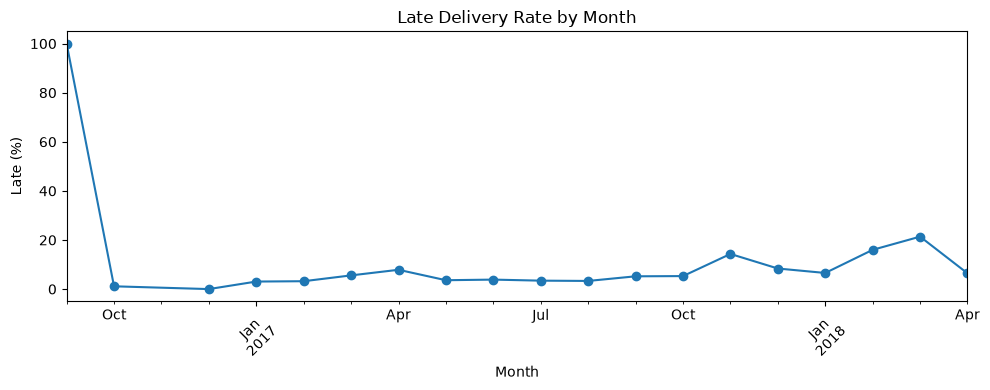

In [21]:
monthly_late = (
    train_df.groupby("purchase_month")["is_late"]
    .mean()
    .mul(100)
)

monthly_late.plot(
    figsize=(10, 4),
    marker="o",
    title="Late Delivery Rate by Month"
)

plt.ylabel("Late (%)")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    CHARTS_DIR / "monthly_late_rate.png",
    bbox_inches="tight"
)

plt.show()

In [22]:
weekday_late = (
    train_df.groupby("purchase_weekday")["is_late"]
    .agg(["count", "mean"])
)

weekday_late["late_%"] = weekday_late["mean"] * 100

display(
    weekday_late.sort_values("late_%", ascending=False)
)

,count,mean,late_%
purchase_weekday,,,
Monday,10734,0.100149,10.014906
Friday,9884,0.094699,9.469850
Tuesday,10729,0.092646,9.264610
Saturday,7593,0.089688,8.968787
Wednesday,10339,0.086082,8.608183
Sunday,8245,0.083808,8.380837
Thursday,10005,0.082859,8.285857


In [23]:
train_df["actual_delivery_days"] = (
    train_df["order_delivered_customer_date"]
    - train_df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

train_df["estimated_delivery_days"] = (
    train_df["order_estimated_delivery_date"]
    - train_df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

train_df[
    ["actual_delivery_days", "estimated_delivery_days"]
].describe()

,actual_delivery_days,estimated_delivery_days
count,67529.000000,67529.000000
mean,13.824217,24.595253
std,10.248897,8.018400
min,0.533414,7.005127
25%,7.450845,19.543333
50%,11.475266,23.621331
75%,17.189155,28.564965
max,209.628611,155.135463


In [24]:
train_df["purchase_month_num"] = purchase_date.dt.month

train_df["year_end_period"] = (
    train_df["purchase_month_num"].isin([11, 12])
)

train_df.groupby("year_end_period")["is_late"].agg(
    ["count", "mean"]
)

,count,mean
year_end_period,,
False,54727,0.083889
True,12802,0.117560


In [25]:
print(
    "Unique customer ZIP prefixes:",
    train_df["customer_zip_code_prefix"].nunique()
)

zip_summary = (
    train_df.groupby("customer_zip_code_prefix")
    .agg(
        orders=("order_id", "count"),
        late_rate=("is_late", "mean")
    )
)

display(
    zip_summary.sort_values(
        "orders",
        ascending=False
    ).head(20)
)

Unique customer ZIP prefixes: 13748


,orders,late_rate
customer_zip_code_prefix,,
22790,113,0.168142
22793,89,0.359551
24220,82,0.207317
24230,81,0.111111
22775,80,0.175000
29101,73,0.136986
35162,69,0.072464
22631,64,0.125000
37200,63,0.142857


In [27]:
display(
    train_df[
        [
            "mean_seller_latitude",
            "mean_seller_longitude",
            "unique_seller_state_count"
        ]
    ].describe()
)

,mean_seller_latitude,mean_seller_longitude,unique_seller_state_count
count,67365.000000,67365.000000,67529.000000
mean,-22.842682,-47.272688,1.004679
std,2.483332,2.333570,0.069323
min,-32.079231,-63.893565,1.000000
25%,-23.612734,-48.829744,1.000000
50%,-23.414433,-46.755753,1.000000
75%,-21.757321,-46.519201,1.000000
max,-2.501242,-34.855616,3.000000


### Geographic Distance

Seller coordinates are available in the current training artifact, but customer latitude and longitude are not present.

Therefore, customer-to-seller distance cannot currently be calculated. Customer coordinates should be added during the data preparation/feature engineering process if geographic distance is selected as a candidate feature.

In [28]:
train_df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'customer_unique_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state', 'item_count', 'unique_product_count',
       'unique_seller_count_x', 'total_item_price', 'mean_item_price',
       'max_item_price', 'total_freight_value', 'payment_count',
       'payment_type_count', 'max_payment_installments', 'total_payment_value',
       'review_count', 'mean_review_score', 'min_review_score',
       'max_review_score', 'unique_category_count', 'unique_seller_count_y',
       'unique_seller_state_count', 'mean_product_weight_g',
       'max_product_weight_g', 'mean_product_length_cm',
       'mean_product_height_cm', 'mean_product_width_cm',
       'mean_seller_latitude', 'mean_seller_longitude', 'is_late',
       'delivery_label', 'purchase_month', 'purchase

### Geographic Distance

Seller coordinates are available, but customer coordinates are not included in the current dataset.

Therefore, customer-to-seller distance cannot be calculated in this notebook. This feature can be considered later if customer coordinates are added from the geolocation data.

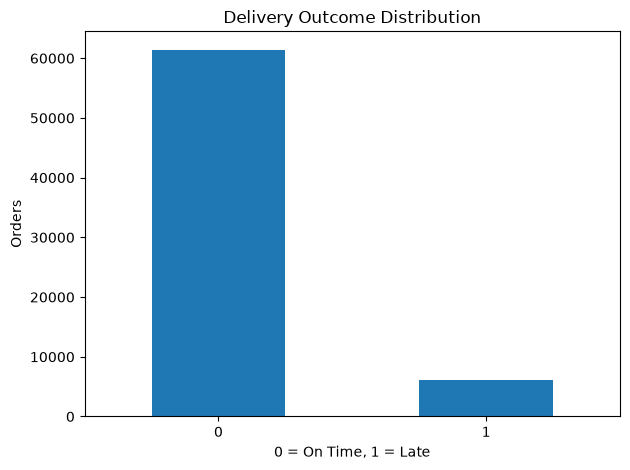

In [29]:
target_counts = train_df["is_late"].value_counts().sort_index()

target_counts.plot(
    kind="bar",
    title="Delivery Outcome Distribution"
)

plt.xlabel("0 = On Time, 1 = Late")
plt.ylabel("Orders")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    CHARTS_DIR / "target_distribution.png",
    bbox_inches="tight"
)

plt.show()